In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro
from scipy.stats import norm
from scipy import stats 

df=pd.read_csv('fr-en-baccalaureat-par-departement.csv',sep=";")

In [2]:
df.head()

,Session,Code académie,Libellé académie,Code département,Libellé département,Voie,Genre,Nombre de présents à l'examen,Nombre d'admis à l'examen,Taux de réussite à l'examen
0,2023,14,Rennes,29,Finistère,Générale,Masculin,2047,2009,98.1
1,2023,14,Rennes,35,Ille-et-Vilaine,Technologique,Masculin,1375,1278,92.9
2,2023,14,Rennes,56,Morbihan,Générale,Féminin,2283,2247,98.4
3,2023,14,Rennes,56,Morbihan,Technologique,Féminin,813,778,95.7
4,2023,14,Rennes,56,Morbihan,Professionnelle,Féminin,1038,944,90.9


In [3]:
df.dtypes

Session                            int64
Code académie                      int64
Libellé académie                     str
Code département                   int64
Libellé département                  str
Voie                                 str
Genre                                str
Nombre de présents à l'examen      int64
Nombre d'admis à l'examen          int64
Taux de réussite à l'examen      float64
dtype: object

#### Les doublons

In [4]:
df[df.duplicated()]

,Session,Code académie,Libellé académie,Code département,Libellé département,Voie,Genre,Nombre de présents à l'examen,Nombre d'admis à l'examen,Taux de réussite à l'examen


#### Les outliers

In [5]:
# Colonnes quantitatives

quanti_col= [col for col in df.columns if df[col].dtype in ['int64', 'float64']] 
print(quanti_col)

['Session', 'Code académie', 'Code département', "Nombre de présents à l'examen", "Nombre d'admis à l'examen", "Taux de réussite à l'examen"]


Maintenant, on va créer la commande qui détecte la distance inter quartiles (le seuil a été fixé ) à 2, mais il peut être fixé à 1.5 par défaut

In [6]:
def detect_outliers(df, feature):
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    return (df[feature] < (Q1 - 2 * IQR)) | (df[feature] > (Q3 + 2 * IQR))

In [7]:
df[detect_outliers(df, "Taux de réussite à l'examen")]

,Session,Code académie,Libellé académie,Code département,Libellé département,Voie,Genre,Nombre de présents à l'examen,Nombre d'admis à l'examen,Taux de réussite à l'examen
526,2024,43,Mayotte,976,Mayotte,Professionnelle,Masculin,1066,708,66.4
1039,2023,33,Guyane,973,Guyane,Professionnelle,Féminin,790,529,67.0
1153,2023,33,Guyane,973,Guyane,Professionnelle,Masculin,838,539,64.3
1166,2023,43,Mayotte,976,Mayotte,Professionnelle,Masculin,995,621,62.4
1409,2025,33,Guyane,973,Guyane,Professionnelle,Masculin,874,552,63.2


### 🔍 Zoom sur les Outliers du Taux de Réussite
L'algorithme (méthode IQR) a identifié 5 établissements comme étant des outliers inférieurs (taux de réussite entre 62% et 67%). 

Après vérification des variables qualitatives (`voie` et `géographie`), il ne s'agit pas d'erreurs de saisie mais de données réelles : ce sont des lycées professionnels situés dans des territoires insulaires/ultramarins. Ces entités combinent deux facteurs explicatifs majeurs : les taux de réussite historiquement plus bas de la voie professionnelle et les défis socio-économiques ou structurels propres à l'isolement insulaire. Ils sont donc conservés dans l'analyse.


#### Les valeurs manquantes

Maintenant, on va s'occuper des valeurs manquantes de la base de données

In [8]:
#On les compte : df est le nom que l'on a donné à notre baase provisoire

nb_na = df.isnull().sum()
print(nb_na[nb_na>0])

Series([], dtype: int64)


Maintenant qu'on les a repérés, on les visualise :

In [9]:
df[df.isnull().any(axis=1)]

,Session,Code académie,Libellé académie,Code département,Libellé département,Voie,Genre,Nombre de présents à l'examen,Nombre d'admis à l'examen,Taux de réussite à l'examen


Une des méthodes est de remplacer par la médiane

In [10]:
values={}
for c in df.columns:
    if df[c].dtype != 'str':
        values[c]=df[c].median()
    else:
        values[c]=df[c].mode()[0]

df.fillna(value=values, inplace=True)

,Session,Code académie,Libellé académie,Code département,Libellé département,Voie,Genre,Nombre de présents à l'examen,Nombre d'admis à l'examen,Taux de réussite à l'examen
0,2023,14,Rennes,29,Finistère,Générale,Masculin,2047,2009,98.1
1,2023,14,Rennes,35,Ille-et-Vilaine,Technologique,Masculin,1375,1278,92.9
2,2023,14,Rennes,56,Morbihan,Générale,Féminin,2283,2247,98.4
3,2023,14,Rennes,56,Morbihan,Technologique,Féminin,813,778,95.7
4,2023,14,Rennes,56,Morbihan,Professionnelle,Féminin,1038,944,90.9
...,...,...,...,...,...,...,...,...,...,...
1813,2023,13,Poitiers,86,Vienne,Professionnelle,Féminin,540,473,87.6
1814,2023,19,Reims,8,Ardennes,Générale,Féminin,683,649,95.0
1815,2023,19,Reims,8,Ardennes,Professionnelle,Féminin,311,255,82.0
1816,2023,19,Reims,10,Aube,Générale,Féminin,823,780,94.8


In [11]:
values #donne les valeurs de remplacement pour chaque colonne

{'Session': np.float64(2024.0),
 'Code académie': np.float64(15.0),
 'Libellé académie': 'Toulouse',
 'Code département': np.float64(52.0),
 'Libellé département': 'Ain',
 'Voie': 'Générale',
 'Genre': 'Féminin',
 "Nombre de présents à l'examen": np.float64(811.5),
 "Nombre d'admis à l'examen": np.float64(728.0),
 "Taux de réussite à l'examen": np.float64(91.6)}

In [12]:
#In vérifie qu'on n'ait plus de valeurs manquantes
df.isnull().sum()

Session                          0
Code académie                    0
Libellé académie                 0
Code département                 0
Libellé département              0
Voie                             0
Genre                            0
Nombre de présents à l'examen    0
Nombre d'admis à l'examen        0
Taux de réussite à l'examen      0
dtype: int64

#### Agrégation

On va regrouper professionnel, technologique et général, voir s'il y a  des grosses disparités

In [13]:
df.groupby('Voie')["Taux de réussite à l'examen"].mean()

Voie
Générale           95.991914
Professionnelle    84.508911
Technologique      91.109406
Name: Taux de réussite à l'examen, dtype: float64

In [14]:
df.groupby("Libellé académie")["Taux de réussite à l'examen"].mean().round(1).sort_values(ascending=True)

Libellé académie
Mayotte             75.6
Guyane              79.9
Créteil             86.6
Versailles          86.9
Amiens              88.0
Reims               88.0
Paris               89.0
La Réunion          89.1
Nice                89.5
Guadeloupe          89.7
Lille               89.8
Strasbourg          90.0
Martinique          90.2
Normandie           90.2
Besançon            90.3
Dijon               90.4
Lyon                90.5
Orléans-Tours       90.6
Aix-Marseille       90.8
Nancy-Metz          91.4
Corse               91.4
Limoges             91.5
Clermont-Ferrand    91.5
Montpellier         91.6
Grenoble            91.8
Bordeaux            91.8
Poitiers            91.9
Nantes              92.6
Toulouse            92.9
Rennes              94.4
Name: Taux de réussite à l'examen, dtype: float64

In [15]:
df.groupby("Libellé académie")["Nombre de présents à l'examen"].mean().round(1).sort_values(ascending=True)

Libellé académie
Corse                236.5
Limoges              389.7
Besançon             521.8
Clermont-Ferrand     563.2
Reims                566.2
Toulouse             664.6
Dijon                668.5
Guyane               689.7
Martinique           708.8
Poitiers             742.8
Orléans-Tours        746.3
Montpellier          972.9
Guadeloupe           989.8
Nancy-Metz           998.6
Mayotte             1034.4
Amiens              1165.5
Normandie           1178.1
Bordeaux            1188.0
Grenoble            1264.7
Aix-Marseille       1350.6
Nantes              1428.7
Rennes              1567.7
Strasbourg          1643.2
Nice                1799.5
La Réunion          1987.0
Lyon                2094.5
Versailles          2987.1
Créteil             3066.8
Lille               3831.8
Paris               4120.7
Name: Nombre de présents à l'examen, dtype: float64

# Maintenant, un peu de visualisation

#### Histogramme sur la distribution des prix totaux des voyages

Cet exemple utilise matplotlib pour générer un histogramme

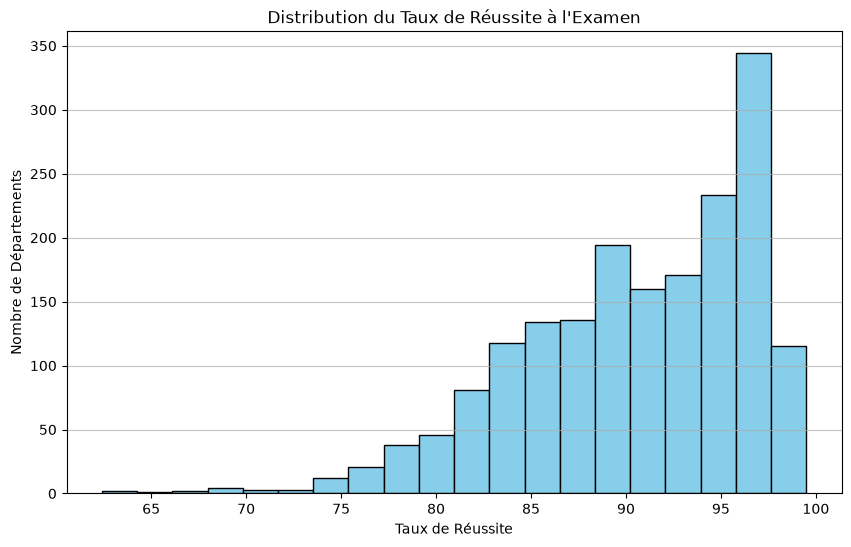

In [16]:
# Le DataFrame nettoyé est déjà présent dans le notebook
data = df.copy()

# Si vous voulez lire le fichier à partir d'un chemin précis, utilisez :
# data = pd.read_csv(r"C:\chemin\vers\Données+clients+VertiGo+nettoyées.csv")

plt.figure(figsize=(10, 6))
plt.hist(data["Taux de réussite à l'examen"], bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution du Taux de Réussite à l\'Examen')
plt.xlabel('Taux de Réussite')
plt.ylabel('Nombre de Départements')
plt.grid(axis='y', alpha=0.75)
plt.show()


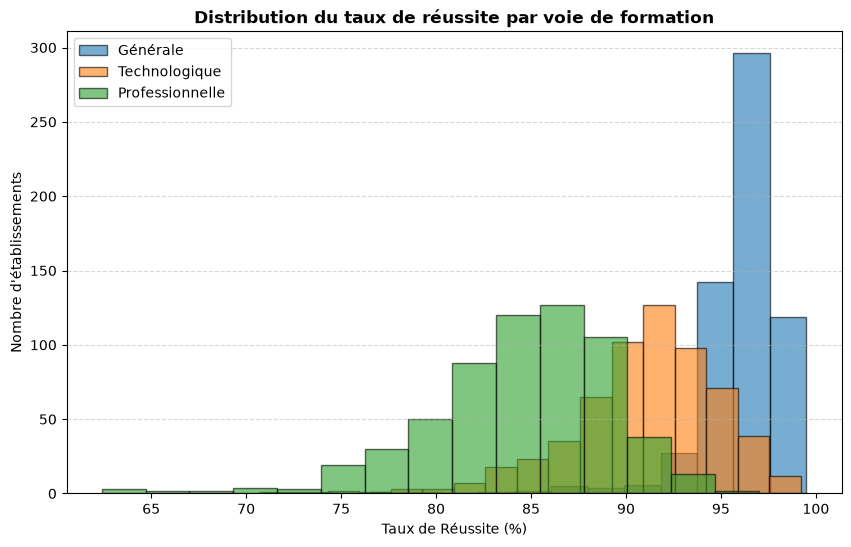

In [17]:
plt.figure(figsize=(10, 6))

# On trace un histogramme pour chaque voie avec de la transparence (alpha)
for voie in df['Voie'].unique():
    subset = df[df['Voie'] == voie]
    plt.hist(subset["Taux de réussite à l'examen"], bins=15, alpha=0.6, label=voie, edgecolor='black')

plt.title("Distribution du taux de réussite par voie de formation", fontsize=12, fontweight='bold')
plt.xlabel("Taux de Réussite (%)")
plt.ylabel("Nombre d'établissements")
plt.legend() # Pour afficher la couleur de chaque filière
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.savefig('distribution_voies.png', dpi=300, bbox_inches='tight')
plt.show()

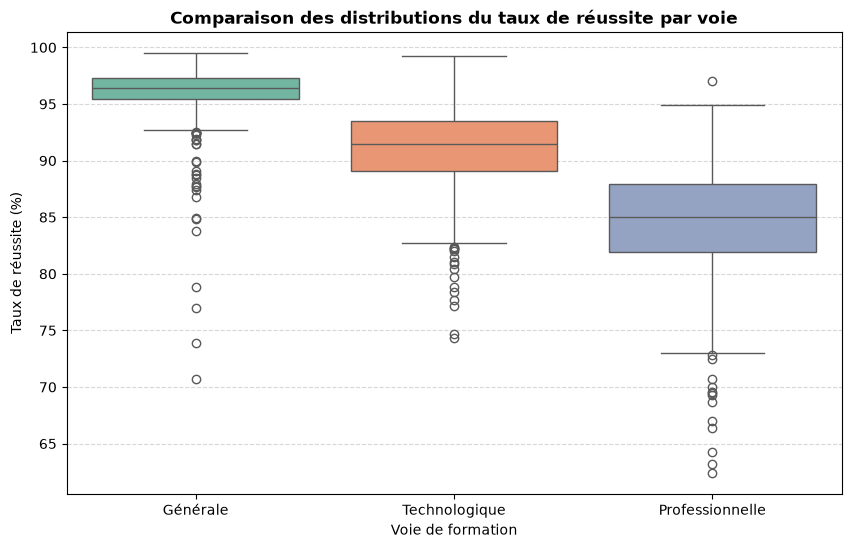

In [18]:
plt.figure(figsize=(10, 6))
# On trace un boxplot du taux de réussite pour chaque voie
sns.boxplot(data=df, x='Voie', y="Taux de réussite à l'examen", palette="Set2", hue='Voie')  # showfliers=True pour afficher les outliers

plt.title("Comparaison des distributions du taux de réussite par voie", fontsize=12, fontweight='bold')
plt.xlabel("Voie de formation")
plt.ylabel("Taux de réussite (%)")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.savefig('boxplot_voies.png', dpi=300, bbox_inches='tight')
plt.show()

In [19]:
# On crée le tableau agrégé par département
df_departement = df.groupby(['Code département', 'Libellé département'])["Taux de réussite à l'examen"].mean().round(1).reset_index()

# On l'exporte en CSV propre pour Power BI
df_departement.to_csv('reussite_bac_par_departement.csv', index=False, sep=';')


In [20]:
df[(df['Voie'] == 'Professionnelle') & (df["Taux de réussite à l'examen"] > 96)]

,Session,Code académie,Libellé académie,Code département,Libellé département,Voie,Genre,Nombre de présents à l'examen,Nombre d'admis à l'examen,Taux de réussite à l'examen
729,2023,16,Toulouse,32,Gers,Professionnelle,Féminin,231,224,97.0


In [21]:
# 1. Comparaison globale nationale par Genre
print("--- Taux de réussite moyen par Genre ---")
print(df.groupby('Genre')["Taux de réussite à l'examen"].mean().round(1))

# 2. Analyse croisée : Genre ET Voie de formation (Encore plus intéressant !)
print("\n--- Taux de réussite croisé (Voie et Genre) ---")
analyse_croisee = df.groupby(['Voie', 'Genre'])["Taux de réussite à l'examen"].mean().round(1).reset_index()
print(analyse_croisee)


--- Taux de réussite moyen par Genre ---
Genre
Féminin     91.9
Masculin    89.1
Name: Taux de réussite à l'examen, dtype: float64

--- Taux de réussite croisé (Voie et Genre) ---
              Voie     Genre  Taux de réussite à l'examen
0         Générale   Féminin                         96.7
1         Générale  Masculin                         95.3
2  Professionnelle   Féminin                         86.7
3  Professionnelle  Masculin                         82.3
4    Technologique   Féminin                         92.5
5    Technologique  Masculin                         89.8


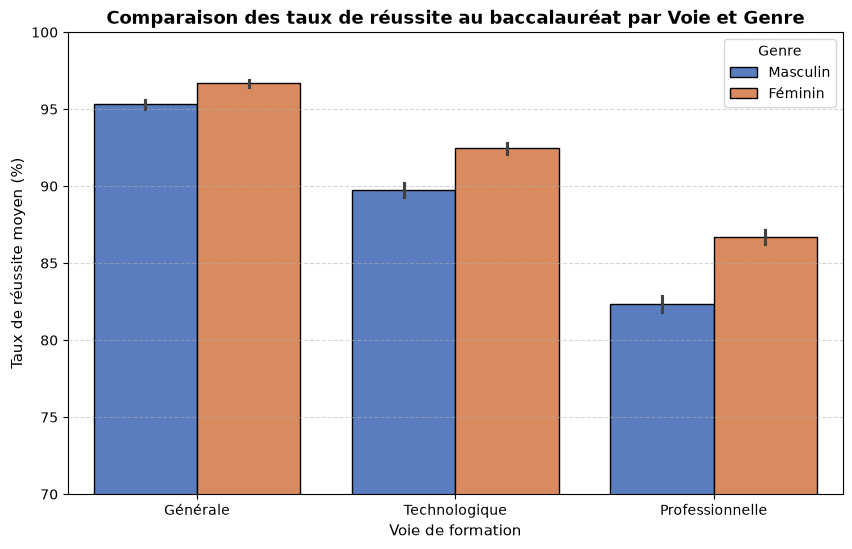

In [22]:
plt.figure(figsize=(10, 6))

# Tracé d'un graphique à barres comparatif Genre / Voie
sns.barplot(
    data=df, 
    x='Voie', 
    y="Taux de réussite à l'examen", 
    hue='Genre', 
    palette='muted', 
    edgecolor='black'
)

# Ajustements et finitions professionnels
plt.title("Comparaison des taux de réussite au baccalauréat par Voie et Genre", fontsize=13, fontweight='bold')
plt.xlabel("Voie de formation", fontsize=11)
plt.ylabel("Taux de réussite moyen (%)", fontsize=11)
plt.ylim(70, 100) # Zoom sur la zone utile pour bien accentuer les écarts
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Sauvegarde de l'image avant l'affichage pour éviter le carré blanc
plt.savefig('comparaison_genre_voie.png', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
# 3. VALIDER STATISTIQUEMENT L'ÉCART DE GENRE (L'apport SciPy)
# Est-ce que la différence de réussite entre filles et garçons en Voie Pro est significative ?
voie_pro_f = df[(df["Voie"] == "Professionnelle") & (df["Genre"] == "Féminin")][
    "Taux de réussite à l'examen"
]
voie_pro_m = df[(df["Voie"] == "Professionnelle") & (df["Genre"] == "Masculin")][
    "Taux de réussite à l'examen"
]

# Test de Student pour échantillons indépendants
t_stat, p_value = stats.ttest_ind(voie_pro_f, voie_pro_m, equal_var=False)

print("\n--- TEST STATISTIQUE (SciPy) ---")
print(f"T-statistic : {t_stat:.4f}")
print(f"P-value : {p_value:.4e}")
if p_value < 0.05:
    print(
        "👉 L'écart de réussite entre les genres en voie professionnelle est STATISTIQUEMENT SIGNIFICATIF (p < 0.05)."
    )
else:
    print(
        "👉 L'écart n'est pas statistiquement significatif au seuil de 5%."
    )


--- TEST STATISTIQUE (SciPy) ---
T-statistic : 12.3363
P-value : 2.9895e-31
👉 L'écart de réussite entre les genres en voie professionnelle est STATISTIQUEMENT SIGNIFICATIF (p < 0.05).
